# 01 · Regresión lineal univariable desde cero

Semana 1. Problema: predecir el tiempo de 5K (min) a partir del ritmo medio de las series de 1 km (min/km). Datos **sintéticos** generados con una relación lineal + ruido.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 4)

## 1. Datos

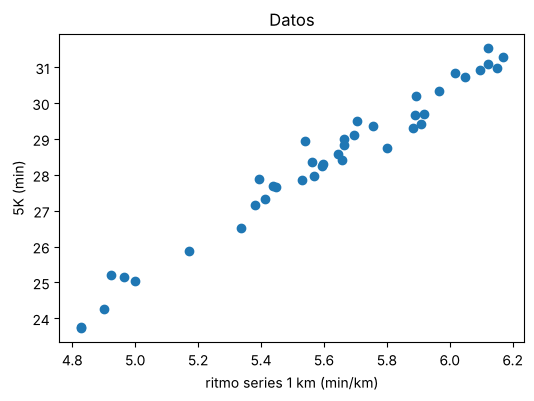

In [2]:
m = 40
x = np.random.uniform(4.8, 6.2, m)            # 1 km rep pace (min/km)
y = 5.3 * x - 1.2 + np.random.normal(0, 0.4, m)  # 5K time (min)
plt.scatter(x, y); plt.xlabel("ritmo series 1 km (min/km)"); plt.ylabel("5K (min)"); plt.title("Datos"); plt.show()

## 2. Modelo y función de coste
$f_{w,b}(x)=wx+b$, $J(w,b)=\frac{1}{2m}\sum (f(x^{(i)})-y^{(i)})^2$

In [3]:
def predict(x, w, b):
    return w * x + b

def compute_cost(x, y, w, b):
    m = x.shape[0]
    err = predict(x, w, b) - y
    return (err ** 2).sum() / (2 * m)

print("J(0,0) =", compute_cost(x, y, 0, 0))
print("J(5,0) =", compute_cost(x, y, 5, 0))

J(0,0) = 404.37562947028545
J(5,0) = 0.12789453518663002


## 3. Gradiente
$\partial J/\partial w = \frac1m\sum(f-y)x$, $\partial J/\partial b=\frac1m\sum(f-y)$

In [4]:
def compute_gradient(x, y, w, b):
    m = x.shape[0]
    err = predict(x, w, b) - y
    return (err * x).sum() / m, err.sum() / m

# numerical check (finite differences) — always worth doing once
eps = 1e-6
dw, db = compute_gradient(x, y, 1.0, 1.0)
dw_num = (compute_cost(x, y, 1 + eps, 1) - compute_cost(x, y, 1 - eps, 1)) / (2 * eps)
print(f"analytic {dw:.6f}  numeric {dw_num:.6f}")

analytic -122.580094  numeric -122.580094


## 4. Descenso de gradiente

In [5]:
def gradient_descent(x, y, w, b, alpha, iters):
    history = []
    for _ in range(iters):
        dw, db = compute_gradient(x, y, w, b)   # both with OLD values
        w, b = w - alpha * dw, b - alpha * db   # simultaneous update
        history.append(compute_cost(x, y, w, b))
    return w, b, history

w, b, hist = gradient_descent(x, y, 0.0, 0.0, alpha=0.02, iters=20000)
print(f"w = {w:.3f}, b = {b:.3f}, J = {hist[-1]:.4f}")
w_ls, b_ls = np.polyfit(x, y, 1)
print(f"least squares (numpy): w = {w_ls:.3f}, b = {b_ls:.3f}")

w = 5.296, b = -1.319, J = 0.0605
least squares (numpy): w = 5.374, b = -1.759


> Fíjate: tras 20.000 iteraciones **aún no** coincide del todo con la solución exacta. No es un bug: el valle de $J$ es muy alargado porque $x$ no está centrado (ver sección 6). En la semana 2 la normalización lo arregla en ~300 iteraciones.

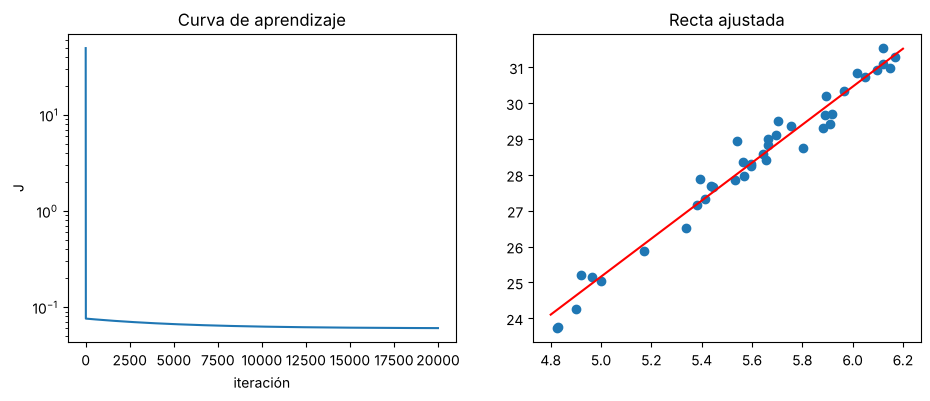

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist); ax[0].set_yscale("log"); ax[0].set_xlabel("iteración"); ax[0].set_ylabel("J"); ax[0].set_title("Curva de aprendizaje")
xs = np.linspace(4.8, 6.2, 50)
ax[1].scatter(x, y); ax[1].plot(xs, predict(xs, w, b), "r"); ax[1].set_title("Recta ajustada")
plt.show()

## 5. Efecto de la tasa de aprendizaje α
Observa: con α grande **diverge**. Sin escalar $x$ (valores ~5) el α máximo estable es pequeño y hay que iterar mucho: lo arreglaremos en la semana 2.

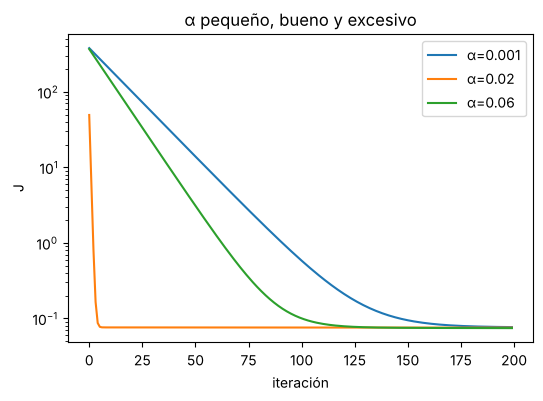

In [7]:
for alpha in [0.001, 0.02, 0.06]:
    _, _, h = gradient_descent(x, y, 0.0, 0.0, alpha, 200)
    plt.plot(h, label=f"α={alpha}")
plt.yscale("log"); plt.legend(); plt.xlabel("iteración"); plt.ylabel("J"); plt.title("α pequeño, bueno y excesivo"); plt.show()

## 6. Curvas de nivel de J

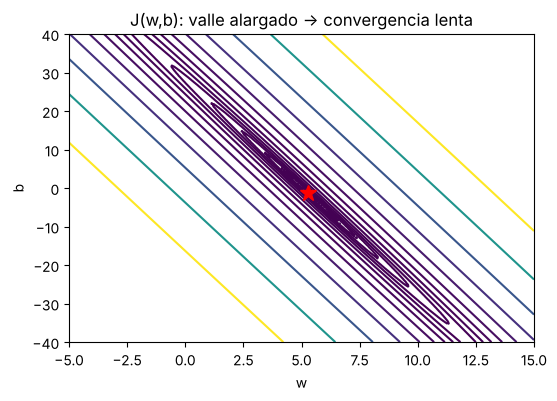

In [8]:
W, B = np.meshgrid(np.linspace(-5, 15, 200), np.linspace(-40, 40, 200))
J = np.array([[compute_cost(x, y, wi, bi) for wi, bi in zip(rw, rb)] for rw, rb in zip(W, B)])
plt.contour(W, B, J, levels=np.logspace(-1, 3, 15)); plt.plot(w, b, "r*", ms=12)
plt.xlabel("w"); plt.ylabel("b"); plt.title("J(w,b): valle alargado → convergencia lenta"); plt.show()

> **Para pensar:** ¿por qué el valle es tan alargado? Pista: compara la escala de $x$ (≈5) con la de la columna de unos que multiplica a $b$.